# Predicting Wildfire Ignition Days from Weather — E178 Final Project
**Question:** Does daily weather predict whether a wildfire starts in California *better than the calendar alone*?

**Target:** `FIRE_START_DAY` (bool) · **Primary metric:** PR-AUC (average precision) on a held-out time block (2016–2023), compared against a month-only baseline.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng_seed = 178

# 1. Load data

In [2]:
raw = pd.read_csv("CA_Weather_Fire_Dataset_1984-2025.csv", parse_dates=["DATE"])
raw.info()
raw.head()

<class 'pandas.DataFrame'>
RangeIndex: 14988 entries, 0 to 14987
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   DATE                   14988 non-null  datetime64[us]
 1   PRECIPITATION          14987 non-null  float64       
 2   MAX_TEMP               14987 non-null  float64       
 3   MIN_TEMP               14987 non-null  float64       
 4   AVG_WIND_SPEED         14976 non-null  float64       
 5   FIRE_START_DAY         14988 non-null  bool          
 6   YEAR                   14988 non-null  int64         
 7   TEMP_RANGE             14987 non-null  float64       
 8   WIND_TEMP_RATIO        14976 non-null  float64       
 9   MONTH                  14988 non-null  int64         
 10  SEASON                 14988 non-null  str           
 11  LAGGED_PRECIPITATION   14988 non-null  float64       
 12  LAGGED_AVG_WIND_SPEED  14988 non-null  float64       
 13  DAY_OF_YEAR 

,DATE,PRECIPITATION,MAX_TEMP,MIN_TEMP,AVG_WIND_SPEED,FIRE_START_DAY,YEAR,TEMP_RANGE,WIND_TEMP_RATIO,MONTH,SEASON,LAGGED_PRECIPITATION,LAGGED_AVG_WIND_SPEED,DAY_OF_YEAR
0,1984-01-01,0.0,79.0,51.0,4.70,False,1984,28.0,0.059494,1,Winter,0.0,4.700,1
1,1984-01-02,0.0,71.0,46.0,5.59,False,1984,25.0,0.078732,1,Winter,0.0,5.145,2
2,1984-01-03,0.0,70.0,47.0,5.37,False,1984,23.0,0.076714,1,Winter,0.0,5.220,3
3,1984-01-04,0.0,76.0,45.0,4.70,False,1984,31.0,0.061842,1,Winter,0.0,5.090,4
4,1984-01-05,0.0,74.0,49.0,5.14,False,1984,25.0,0.069459,1,Winter,0.0,5.100,5


# 2. Data health
## 2.1 Missing values (explicit NaNs)

In [3]:
na = raw.isna().sum()
print(na[na > 0])
print(f"\nRows with any NaN: {raw.isna().any(axis=1).sum()} of {len(raw)} ({raw.isna().any(axis=1).mean():.2%})")
raw[raw.isna().any(axis=1)][["DATE", "PRECIPITATION", "MAX_TEMP", "MIN_TEMP", "AVG_WIND_SPEED"]]

PRECIPITATION       1
MAX_TEMP            1
MIN_TEMP            1
AVG_WIND_SPEED     12
TEMP_RANGE          1
WIND_TEMP_RATIO    12
dtype: int64

Rows with any NaN: 12 of 14988 (0.08%)


,DATE,PRECIPITATION,MAX_TEMP,MIN_TEMP,AVG_WIND_SPEED
4808,1997-03-01,0.0,64.0,46.0,NaN
4809,1997-03-02,0.0,60.0,45.0,NaN
4810,1997-03-03,0.0,59.0,47.0,NaN
14879,2024-09-26,0.0,70.0,60.0,NaN
14971,2024-12-27,0.0,61.0,49.0,NaN
14972,2024-12-28,0.0,59.0,53.0,NaN
14973,2024-12-29,0.0,58.0,47.0,NaN
14974,2024-12-30,0.0,62.0,52.0,NaN
14975,2024-12-31,NaN,NaN,NaN,NaN
14976,2025-01-01,0.0,59.0,47.0,NaN


Only 13 rows have NaNs, clustered in Mar 1997 and late 2024–Jan 2025. `TEMP_RANGE` and `WIND_TEMP_RATIO` are derived from the raw columns, so their NaNs follow from those.

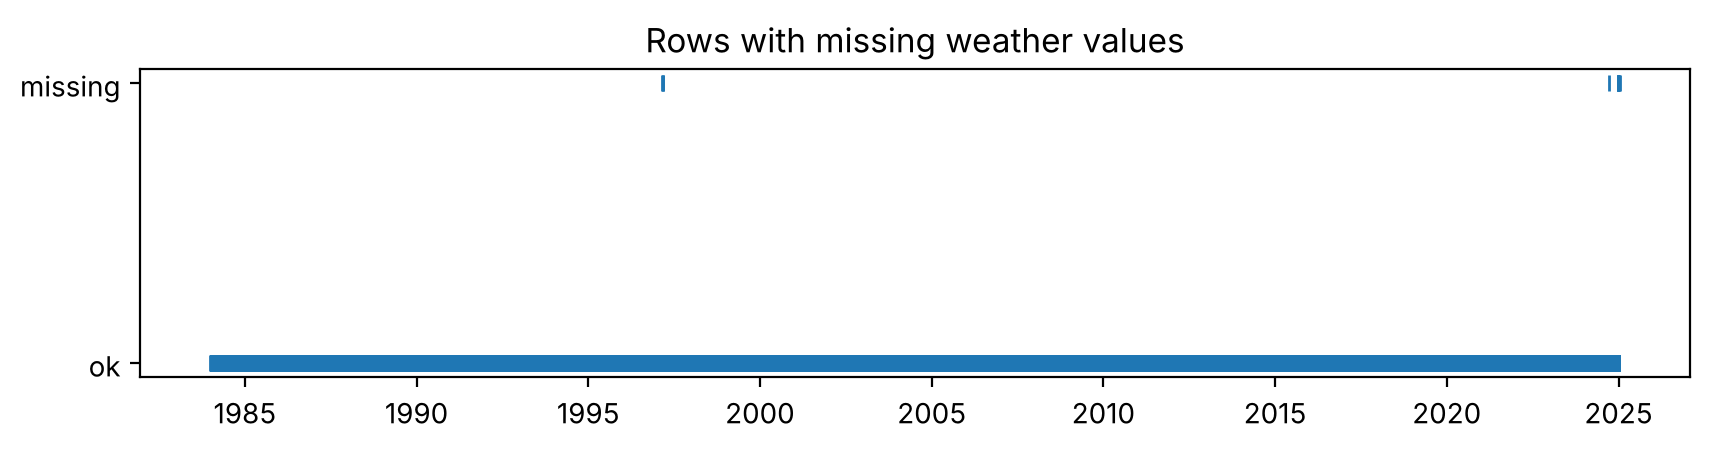

In [4]:
# Visualise where missing values fall in time
miss = raw.set_index("DATE").isna().any(axis=1)
plt.figure(figsize=(10, 2))
plt.plot(miss.index, miss.astype(int), "|")
plt.yticks([0, 1], ["ok", "missing"]); plt.title("Rows with missing weather values")
plt.show()

## 2.2 Date continuity and duplicates

In [5]:
full_range = pd.date_range(raw.DATE.min(), raw.DATE.max(), freq="D")
print("Date range:", raw.DATE.min().date(), "to", raw.DATE.max().date())
print("Missing calendar days:", len(full_range.difference(raw.DATE)))
print("Duplicate dates:", raw.DATE.duplicated().sum())

Date range: 1984-01-01 to 2025-01-12
Missing calendar days: 0
Duplicate dates: 0


## 2.3 Hidden missingness in the label
NaN counts say the label is complete, but the fire rate per year shows otherwise:

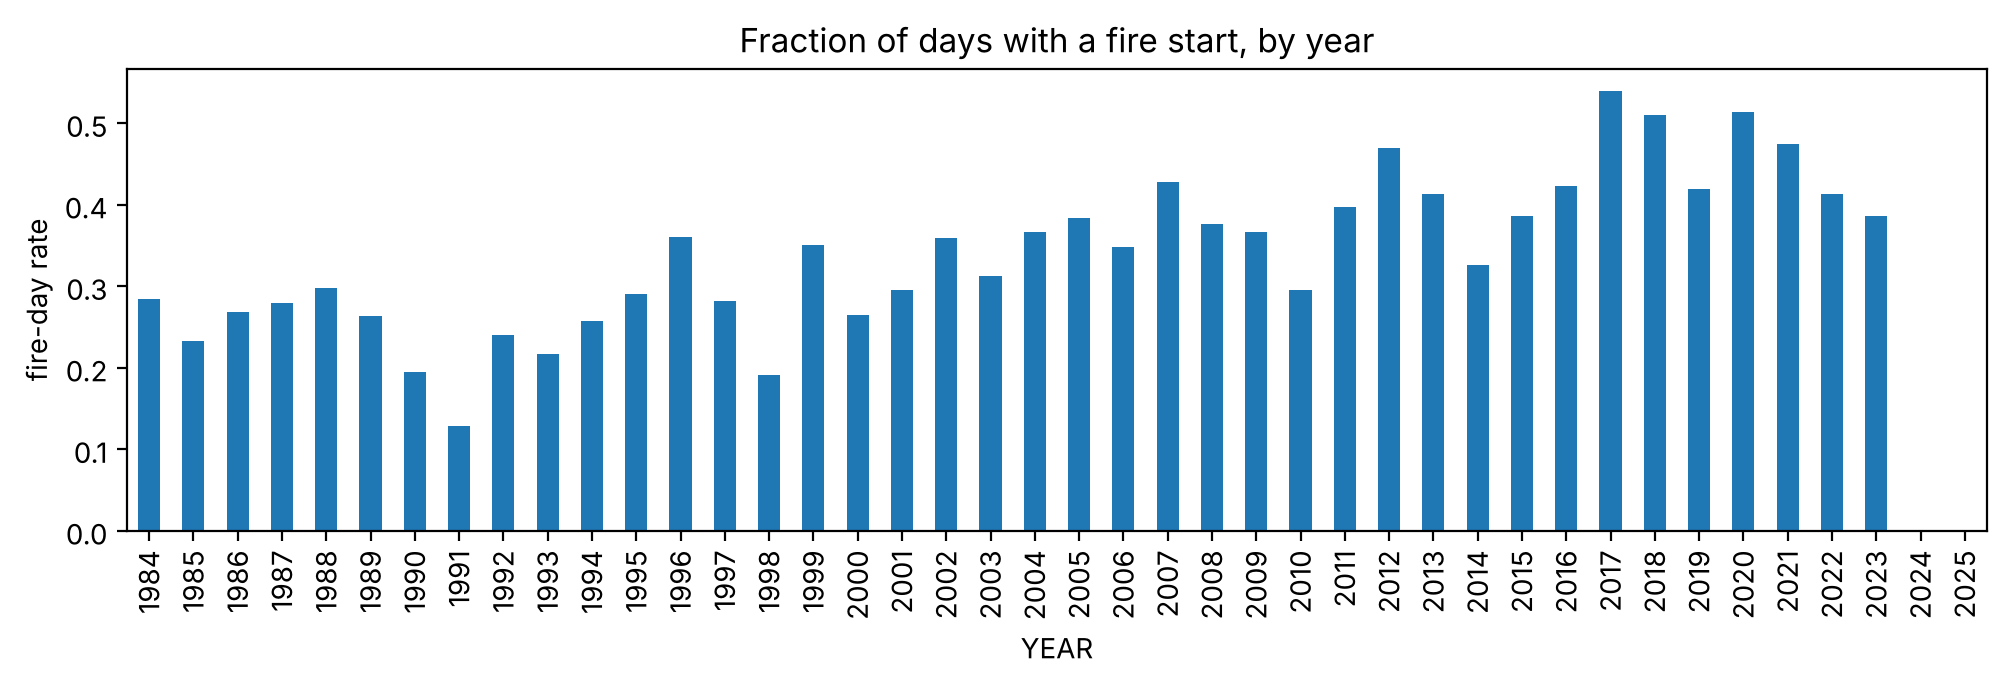

Last recorded fire start: 2023-12-22
Fire days in 2024–2025: 0


In [6]:
yearly = raw.groupby("YEAR").FIRE_START_DAY.mean()
yearly.plot(kind="bar", figsize=(12, 3), title="Fraction of days with a fire start, by year")
plt.ylabel("fire-day rate"); plt.show()
print("Last recorded fire start:", raw.loc[raw.FIRE_START_DAY, "DATE"].max().date())
print("Fire days in 2024–2025:", raw.loc[raw.YEAR >= 2024, "FIRE_START_DAY"].sum())

**Zero fire days in 2024–2025 is not real**. It means the fire records stop after Dec 2023 and those days default to `False`. Keeping them would add ~380 false negatives. **We drop 2024+.**

The rate also trends upward (~0.25 in the 1980s → ~0.45 by 2016–2023). That's distribution shift, so a random train/test split would be overly optimistic. We split by time instead.

## 2.4 Ranges / outliers and feature definitions

In [7]:
raw.describe().T

,count,mean,min,25%,50%,75%,max,std
DATE,14988,2004-07-07 12:00:00,1984-01-01 00:00:00,1994-04-04 18:00:00,2004-07-07 12:00:00,2014-10-10 06:00:00,2025-01-12 00:00:00,NaN
PRECIPITATION,14987.0,0.032315,0.0,0.0,0.0,0.0,4.53,0.179544
MAX_TEMP,14987.0,70.534997,50.0,65.0,70.0,75.0,106.0,7.263447
MIN_TEMP,14987.0,56.494095,33.0,51.0,57.0,62.0,77.0,6.767685
AVG_WIND_SPEED,14976.0,7.435098,1.79,6.04,7.16,8.5,26.17,2.129985
YEAR,14988.0,2004.016813,1984.0,1994.0,2004.0,2014.0,2025.0,11.843342
TEMP_RANGE,14987.0,14.040902,2.0,10.0,12.0,17.0,41.0,5.995327
WIND_TEMP_RATIO,14976.0,0.107019,0.023553,0.085238,0.102222,0.120462,0.459123,0.03563
MONTH,14988.0,6.518281,1.0,4.0,7.0,10.0,12.0,3.451037
LAGGED_PRECIPITATION,14988.0,0.226188,0.0,0.0,0.0,0.06,8.18,0.648705


In [8]:
# Check how the LAGGED_ columns are built (looks like a 7-day trailing window *including today*)
chk = raw[["AVG_WIND_SPEED", "LAGGED_AVG_WIND_SPEED", "PRECIPITATION", "LAGGED_PRECIPITATION"]].copy()
chk["wind_7d_mean"] = raw.AVG_WIND_SPEED.rolling(7, min_periods=1).mean()
chk["precip_7d_sum"] = raw.PRECIPITATION.rolling(7, min_periods=1).sum()
chk.head(10)

,AVG_WIND_SPEED,LAGGED_AVG_WIND_SPEED,PRECIPITATION,LAGGED_PRECIPITATION,wind_7d_mean,precip_7d_sum
0,4.70,4.700000,0.0,0.0,4.700000,0.0
1,5.59,5.145000,0.0,0.0,5.145000,0.0
2,5.37,5.220000,0.0,0.0,5.220000,0.0
3,4.70,5.090000,0.0,0.0,5.090000,0.0
4,5.14,5.100000,0.0,0.0,5.100000,0.0
5,7.38,5.480000,0.0,0.0,5.480000,0.0
6,5.82,5.528571,0.0,0.0,5.528571,0.0
7,3.36,5.337143,0.0,0.0,5.337143,0.0
8,6.71,5.497143,0.0,0.0,5.497143,0.0
9,4.70,5.401429,0.0,0.0,5.401429,0.0


Notes to verify as a group:
- `MAX_TEMP` never drops below 50 °F, which suggests weather from a single mild station (it's not a statewide average), while the fire label covers all of California. Find out which station it is (check the dataset source) and state this as a limitation.
- The lagged features include the current day. That's fine when predicting *same-day* ignition. To claim *next-day forecasting*, shift the features by one day.

## 2.5 Class balance and seasonality

FIRE_START_DAY
False    0.659754
True     0.340246
Name: proportion, dtype: float64


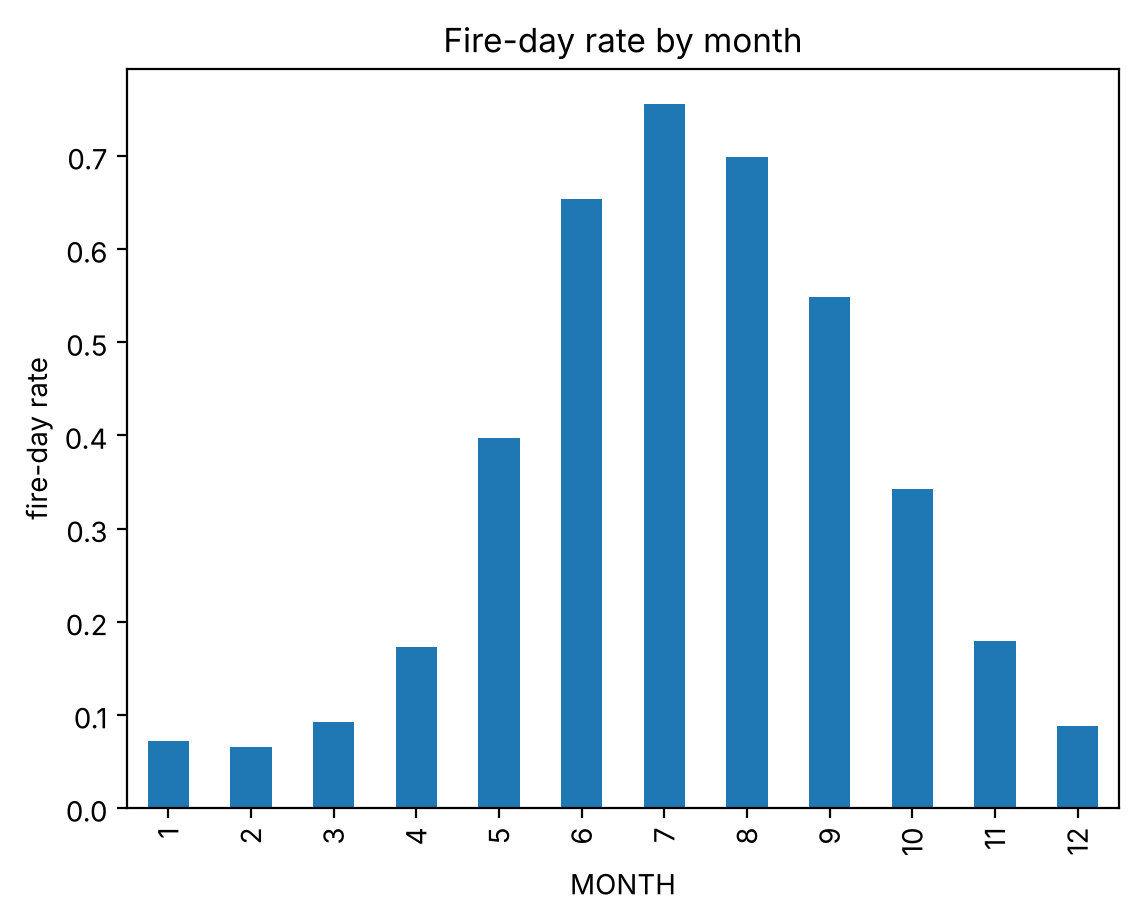

In [9]:
print(raw.loc[raw.YEAR <= 2023, "FIRE_START_DAY"].value_counts(normalize=True))
raw[raw.YEAR <= 2023].groupby("MONTH").FIRE_START_DAY.mean().plot(kind="bar", title="Fire-day rate by month")
plt.ylabel("fire-day rate"); plt.show()

Seasonality is strong (~7% in Jan vs ~74% in Jul). A model can look good just by learning the month, so the **month-only model is our baseline to beat**.

# 3. Clean dataset

In [10]:
data = raw[raw.YEAR <= 2023].dropna().reset_index(drop=True)
print(f"Kept {len(data)} of {len(raw)} rows")

weather_cols = ["PRECIPITATION", "MAX_TEMP", "MIN_TEMP", "AVG_WIND_SPEED", "TEMP_RANGE",
                "LAGGED_PRECIPITATION", "LAGGED_AVG_WIND_SPEED"]
target = "FIRE_START_DAY"

train = data[data.YEAR <= 2015]
test  = data[data.YEAR >= 2016]
print("Train:", len(train), "rows, fire rate", round(train[target].mean(), 3))
print("Test: ", len(test),  "rows, fire rate", round(test[target].mean(), 3))

Kept 14607 of 14988 rows


Train: 11685 rows, fire rate 0.31
Test:  2922 rows, fire rate 0.46


# 4. Performance metric and first baselines
**Primary metric:** PR-AUC (average precision). It doesn't depend on a threshold, it focuses on how well we catch fire days, and it's comparable across models. **Secondary:** ROC-AUC, plus recall/precision and a confusion matrix at the chosen operating threshold.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import average_precision_score, roc_auc_score

def evaluate(num_cols, cat_cols=[]):
    ct = make_column_transformer((StandardScaler(), num_cols), (OneHotEncoder(handle_unknown="ignore"), cat_cols))
    model = make_pipeline(ct, LogisticRegression(max_iter=2000))
    model.fit(train[num_cols + cat_cols], train[target])
    p = model.predict_proba(test[num_cols + cat_cols])[:, 1]
    return {"PR-AUC": average_precision_score(test[target], p), "ROC-AUC": roc_auc_score(test[target], p)}

results = pd.DataFrame({
    "No-skill (base rate)": {"PR-AUC": test[target].mean(), "ROC-AUC": 0.5},
    "Month only":           evaluate([], ["MONTH"]),
    "Weather only":         evaluate(weather_cols),
    "Weather + month":      evaluate(weather_cols, ["MONTH"]),
}).T.round(3)
results

,PR-AUC,ROC-AUC
No-skill (base rate),0.460,0.500
Month only,0.782,0.832
Weather only,0.771,0.821
Weather + month,0.810,0.849


# 5. Tuned random forest with time-aware cross-validation
We tune hyperparameters with `TimeSeriesSplit`, so every validation fold comes *after* the data it was trained on. This matches how the model would be used and respects the upward trend in fire days. Scoring uses average precision (PR-AUC), our primary metric. The test set (2016–2023) is not touched during tuning.

In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

features = weather_cols + ["MONTH"]   # trees can split on month directly; no one-hot needed
Xtr, ytr = train[features], train[target]
Xte, yte = test[features], test[target]

tscv = TimeSeriesSplit(n_splits=5)
param_grid = {
    "n_estimators": [200],
    "max_depth": [4, 8, 12, None],
    "min_samples_leaf": [5, 20, 50],
}
grid = GridSearchCV(RandomForestClassifier(random_state=rng_seed, n_jobs=-1),
                    param_grid, cv=tscv, scoring="average_precision", n_jobs=-1)
grid.fit(Xtr, ytr)
print("Best params:", grid.best_params_)
print("Best CV PR-AUC:", round(grid.best_score_, 3))

Best params: {'max_depth': None, 'min_samples_leaf': 20, 'n_estimators': 200}
Best CV PR-AUC: 0.642


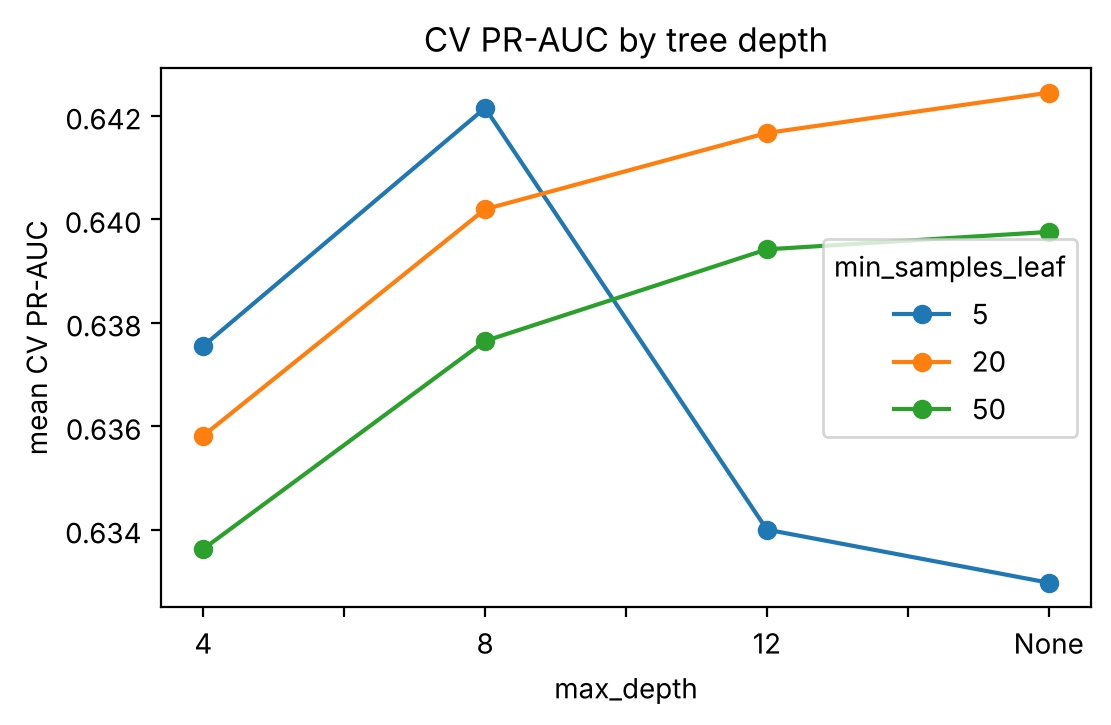

In [13]:
cv_res = pd.DataFrame(grid.cv_results_)
pivot = cv_res.pivot_table(index="param_max_depth", columns="param_min_samples_leaf",
                           values="mean_test_score", dropna=False)
pivot.index = pivot.index.map(lambda v: "None" if pd.isna(v) else int(v))
ax = pivot.plot(marker="o", figsize=(6, 3.5), title="CV PR-AUC by tree depth")
ax.set_xlabel("max_depth"); ax.set_ylabel("mean CV PR-AUC"); ax.legend(title="min_samples_leaf")
plt.show()

## 5.1 Test-set performance vs baselines

In [14]:
rf = grid.best_estimator_            # refit on all of 1984–2015 by GridSearchCV
p_rf = rf.predict_proba(Xte)[:, 1]
results.loc["Random forest (weather + month)"] = [average_precision_score(yte, p_rf), roc_auc_score(yte, p_rf)]
results.round(3)

,PR-AUC,ROC-AUC
No-skill (base rate),0.460,0.500
Month only,0.782,0.832
Weather only,0.771,0.821
Weather + month,0.810,0.849
Random forest (weather + month),0.805,0.848


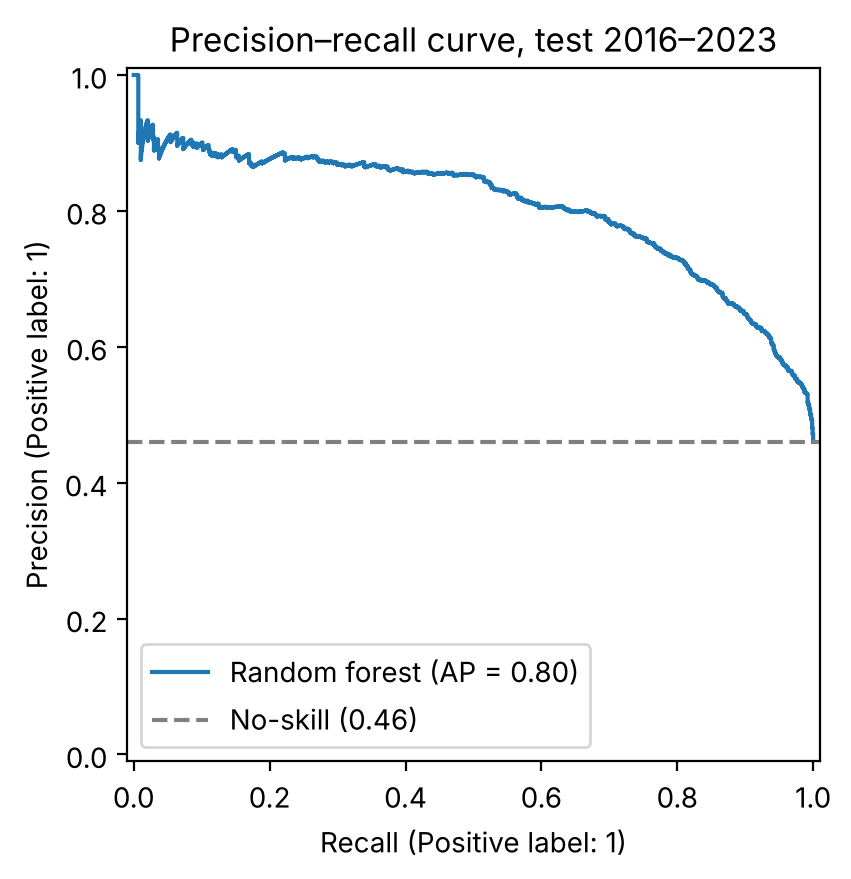

In [15]:
from sklearn.metrics import precision_recall_curve, PrecisionRecallDisplay
fig, ax = plt.subplots(figsize=(6, 4.5))
PrecisionRecallDisplay.from_predictions(yte, p_rf, name="Random forest", ax=ax)
ax.axhline(yte.mean(), ls="--", c="gray", label=f"No-skill ({yte.mean():.2f})")
ax.set_title("Precision–recall curve, test 2016–2023"); ax.legend(); plt.show()

## 5.2 Choosing an operating threshold
For a fire-danger warning, a missed ignition costs more than a false alarm. **Target: catch at least 80% of fire days.**
To keep the test set honest, we pick the threshold on a validation block (2011–2015) using a model trained on 1984–2010, then apply that fixed threshold to the test set.

In [16]:
from sklearn.base import clone
TARGET_RECALL = 0.80

fit_part = train[train.YEAR <= 2010]
val_part = train[train.YEAR >= 2011]
rf_val = clone(rf).fit(fit_part[features], fit_part[target])
p_val = rf_val.predict_proba(val_part[features])[:, 1]

prec, rec, thr = precision_recall_curve(val_part[target], p_val)
# highest threshold that still achieves the target recall on validation
ok = np.where(rec[:-1] >= TARGET_RECALL)[0]
threshold = thr[ok[-1]]
print(f"Chosen threshold: {threshold:.3f}  (validation recall {rec[ok[-1]]:.2f}, precision {prec[ok[-1]]:.2f})")

Chosen threshold: 0.222  (validation recall 0.80, precision 0.61)


Test recall:    0.827
Test precision: 0.705
Test F2:        0.799


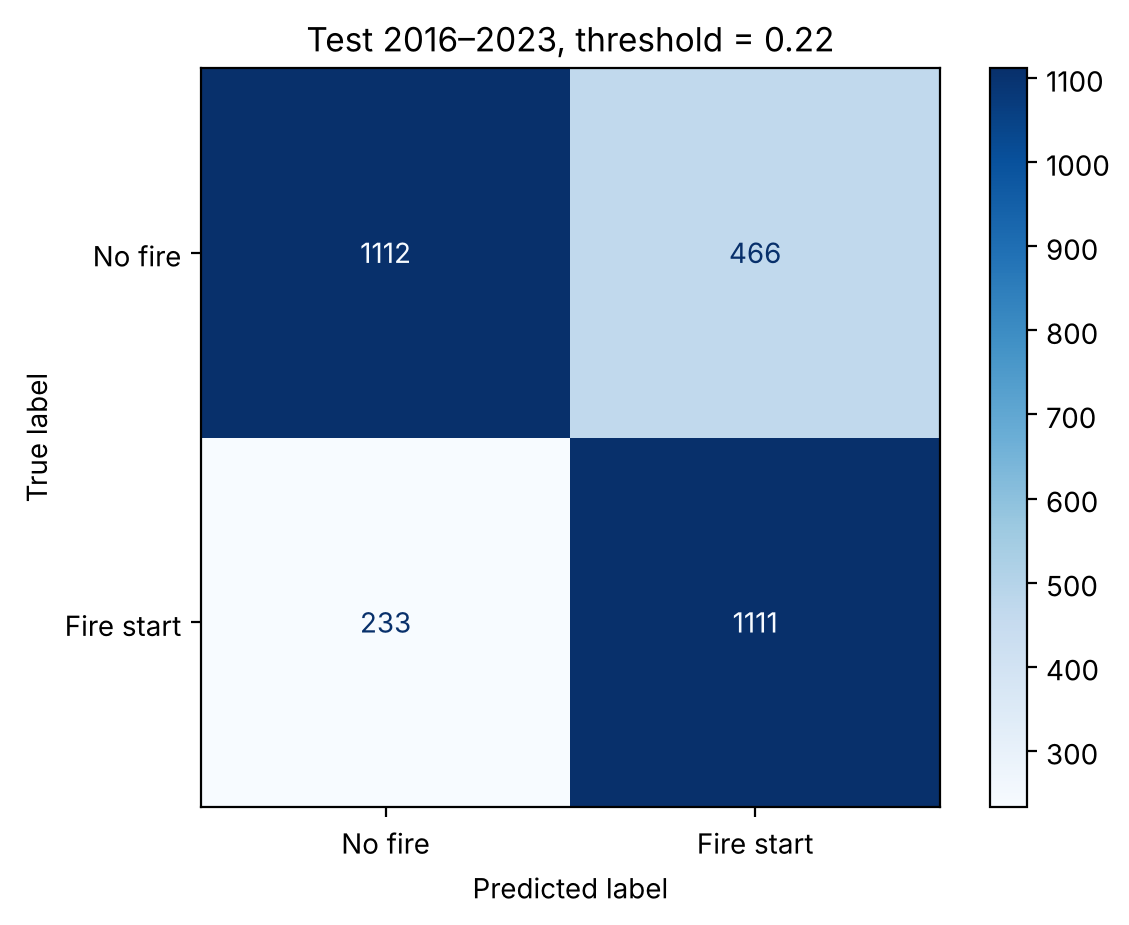

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, fbeta_score
yhat = p_rf >= threshold
print(f"Test recall:    {recall_score(yte, yhat):.3f}")
print(f"Test precision: {precision_score(yte, yhat):.3f}")
print(f"Test F2:        {fbeta_score(yte, yhat, beta=2):.3f}")

ConfusionMatrixDisplay(confusion_matrix(yte, yhat), display_labels=["No fire", "Fire start"]).plot(cmap="Blues", values_format="d")
plt.title(f"Test 2016–2023, threshold = {threshold:.2f}"); plt.show()

## 5.3 Which inputs matter?
Permutation importance on the test set: how much PR-AUC drops when each feature is shuffled.

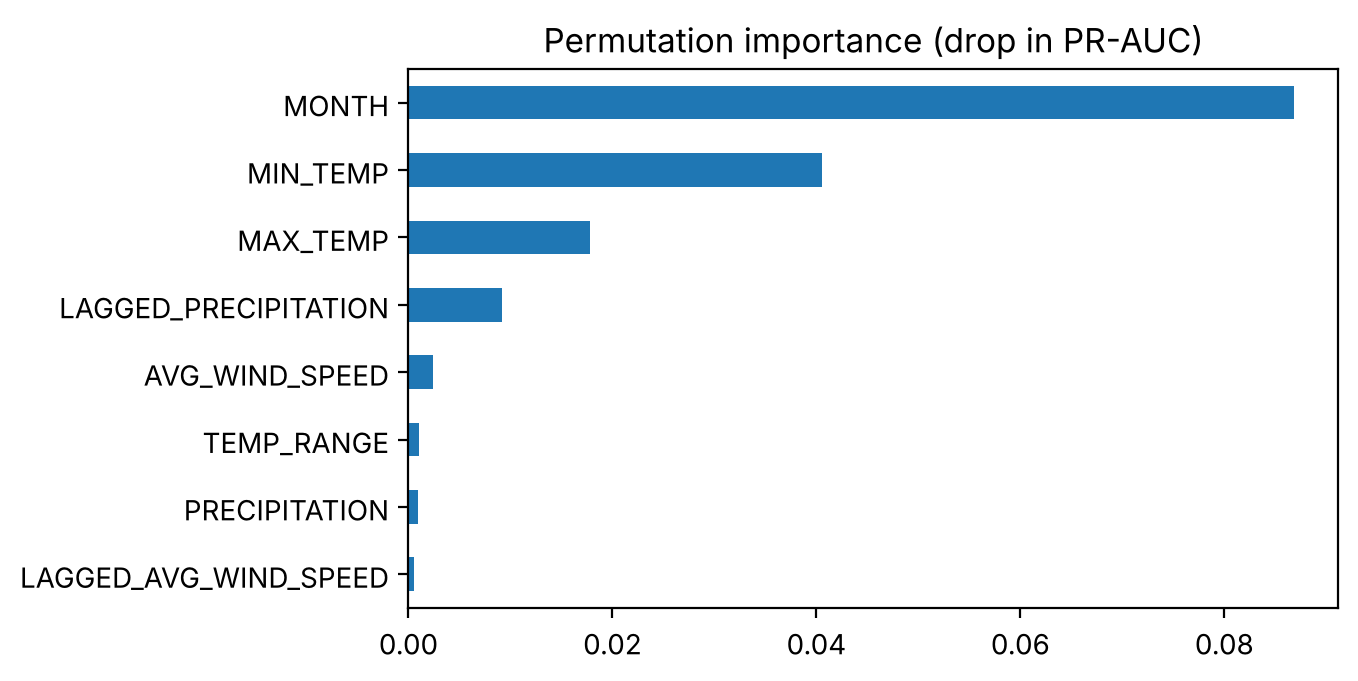

In [18]:
from sklearn.inspection import permutation_importance
imp = permutation_importance(rf, Xte, yte, scoring="average_precision", n_repeats=10, random_state=rng_seed, n_jobs=-1)
pd.Series(imp.importances_mean, index=features).sort_values().plot(kind="barh", figsize=(6, 3.5),
    title="Permutation importance (drop in PR-AUC)")
plt.show()

## 5.4 Takeaways
- The tuned random forest (PR-AUC 0.805) does **no better than plain logistic regression** (0.810). With these 8 features, the model type isn't the bottleneck. Better features are.
- At a threshold picked on validation for 80% recall, the forest catches **~83% of test fire days at ~70% precision**.
- Month is the strongest single input. Min and max temperature and 7-day precipitation add real signal on top. Wind adds almost nothing.
- CV scores (~0.64) are lower than test scores because the early folds have fewer fire days (the base rate rises over time). Compare models against each other, not CV against test.

# 6. Next steps
- Try gradient boosting (`HistGradientBoostingClassifier`) under the same CV setup.
- Engineer drought-style features, e.g. days since last rain or 30-day rolling precipitation and temperature.
- Bootstrap the test PR-AUC to get confidence intervals, so we can tell whether weather + month really beats month only.
- Stretch: add campground usage and biome. These need location-level fire labels (region × day).